# Prediksi Pembatalan Booking Hotel: Kerangka Berpikir Proyek
## Dari pertanyaan bisnis pertama sampai keputusan model demo

Notebook ini merangkum **alur berpikir** satu proyek data science dari nol, untuk dibaca orang lain dari awal sampai akhir. Ia disusun ulang dari notebook latihan yang panjang (Sesi 1–S10) dan rangkaian eksperimen setelahnya; notebook latihan asli tetap ada dan tidak diubah.

**Tiga jenis isi:**

1. **Sel kode** bisa dijalankan ulang berurutan dari atas (Runtime → Run all). Jalur utama: data → audit → SQL → EDA → statistik → kohort → baseline → tuning → eksperimen → simulasi → pembanding acak.
2. **Tabel "hasil tercatat"** di sel markdown: angka dari sesi evaluasi yang sebenarnya (19–20 November 2026), disalin apa adanya. Tidak semua eksperimen diulang di notebook ini — puluhan proses pelatihan dari eksperimen fitur dan tuning diringkas sebagai arsip, bukan dijalankan ulang.
3. **Gambar pratinjau** di sel markdown: hasil visual yang terlihat tanpa menjalankan apa pun — dihasilkan dari sel kode yang sama pada lingkungan tercatat, atau direkonstruksi dari tabel tercatat; keduanya diberi label jelas.

**Lingkungan hasil tercatat:** Google Colab, Python 3.13, scikit-learn 1.6.1, XGBoost 3.4.1, CatBoost 1.2.10. Seluruh **jalur eksekutabel** notebook sudah diverifikasi jalan ujung-ke-ujung pada versi terpin tersebut: semua sel berjalan tanpa error, dan angka jangkar utamanya — AP baseline S9 (0,0939806541915978), AP ketiga pemenang tuning, hasil simulasi harian, dan ekspektasi acak — tereproduksi **bit-for-bit**. Arsip hasil tercatat (grid tuning lengkap, tabel A–E, evaluasi fold, evaluasi test) tetap historis dan memang tidak dijalankan ulang di notebook ini. Sel penyetelan versi ada di awal Bagian 2. Pada versi library lain, hasil yang bergantung model bisa bergeser (teramati langsung saat pengujian: kode dan data sama, versi berbeda, angka berubah), jadi gunakan versi terpin bila ingin angka yang sama persis.

**Framing yang jujur:** proyek ini bukan model yang siap dipakai hotel. Pertanyaannya juga tidak sudah berbentuk skenario H-1 sejak hari pertama — ia berkembang dari audit data, ke pertanyaan bisnis, baru kemudian ke skenario konfirmasi harian. Notebook ini mendokumentasikan apa yang diukur, apa yang berubah, dan apa yang tidak terbukti — termasuk bahwa subset test sudah pernah dievaluasi, sehingga semua hasil setelahnya bersifat eksploratoris.

## 1. Pertanyaan awal

Proyek ini dimulai dari dataset pembatalan booking hotel dan rasa penasaran yang sederhana: **apa yang bisa dipelajari dari data ini untuk membantu hotel mengurangi dampak booking batal?**

Belum ada skenario operasional di titik ini. Yang ada baru dugaan arah: kalau hotel punya cara menandai booking yang berisiko batal, staf bisa menindaklanjuti lebih awal — misalnya menelepon untuk konfirmasi ulang. Bentuk pastinya ("menandai" itu seperti apa, "lebih awal" itu kapan, berapa banyak yang bisa ditindaklanjuti) baru mengerucut setelah data dipahami — ikuti bab-bab berikutnya.

Target prediksi yang akhirnya dipakai: booking berakhir **batal atau no-show** (`is_canceled = 1`).

## 2. Data dan provenance

**Sumber:** Hotel Booking Demand — Nuno Antonio, Ana de Almeida, Luis Nunes (2019), *Data in Brief* 22:41–49.
- Artikel: https://www.sciencedirect.com/science/article/pii/S2352340918315191
- Data resmi (lampiran artikel): https://ars.els-cdn.com/content/image/1-s2.0-S2352340918315191-mmc2.zip
- Versi open access: https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/
- Mirror yang dimuat notebook ini: https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv

Dipakai subset **City Hotel** (file H2 pada rilis resmi): 79.330 booking, 31 kolom.

**Yang sudah diverifikasi (audit pada salinan data dan salinan notebook versi 19 November 2026):**
- File CSV proyek **byte-identik** dengan H2.csv resmi (SHA-256 `5107090ffdc5585a9e18299801e9d85c3b459c235542882183a502a73ef63c4d`). Artinya sama dengan rilis resmi — bukan bukti datanya bersih secara substansi.
- Isi mirror TidyTuesday untuk City Hotel **identik** dengan H2 resmi setelah normalisasi format (nama kolom, padding, NULL, tipe data, kolom tambahan `hotel`).
- Rantai transformasi pada salinan notebook 19 Nov tereproduksi persis (ukuran kohort, pembagian data, label). Ini bukan bukti rantai di notebook lain yang lebih baru.

**Temuan desain dari paper asli:** dataset ini memang dirancang dengan titik waktu data = **H-1** — *"the data point time for each observation was defined as the day prior to each booking's arrival"* — dan nilai variabel diekstrak dari change log booking bila tersedia, untuk mencegah kebocoran informasi masa depan.

**Kriteria kohort proyek ini, mengikuti desain itu:** booking yang **dibuat sebelum H-1** dan **belum batal per H-1** (masih aktif di snapshot H-1).

### Lingkungan tercatat: setel versi dulu (sekali saja)

Hasil proyek ini tercatat pada **Google Colab, Python 3.13, scikit-learn 1.6.1, XGBoost 3.4.1, CatBoost 1.2.10**. Supaya angka hasil run ulang sama persis dengan tabel tercatat, jalankan sel pemasangan di bawah **paling awal**, lalu **restart runtime sekali** (Runtime → Restart runtime), dan lanjutkan dari sel pemeriksaan versi. Tanpa langkah ini notebook tetap jalan, tetapi angka yang bergantung model bisa bergeser — pergeseran seperti ini teramati langsung saat pengujian notebook ini.

In [ ]:
## Pasang versi library persis seperti lingkungan tercatat
# 1. Versi tercatat: scikit-learn 1.6.1, XGBoost 3.4.1, CatBoost 1.2.10 (Python 3.13 di Colab).
# 2. Jalankan sel ini SEKALI, lalu restart runtime (Runtime -> Restart runtime) sebelum lanjut.
#    XGBoost 3.4.1 membutuhkan Python >= 3.12; Colab saat ini memakai Python 3.13, jadi cocok.
%pip install -q scikit-learn==1.6.1 xgboost==3.4.1 catboost==1.2.10


In [ ]:
## Periksa versi yang sedang berjalan dibanding versi tercatat
# 1. Tampilkan versi berjalan (sesudah restart runtime).
import sys
import sklearn, xgboost, catboost
print('Python      :', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('xgboost     :', xgboost.__version__)
print('catboost    :', catboost.__version__)
import pandas as pd, numpy as np
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)

# 2. Bandingkan dengan versi tercatat dan beri peringatan jelas bila berbeda.
versi_tercatat = {'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'catboost': '1.2.10'}
versi_berjalan = {'scikit-learn': sklearn.__version__, 'xgboost': xgboost.__version__, 'catboost': catboost.__version__}
if versi_berjalan == versi_tercatat:
    print('Versi cocok dengan lingkungan tercatat: angka run ulang akan sama persis dengan tabel tercatat.')
else:
    print('PERHATIAN: versi berjalan berbeda dari tercatat:', versi_tercatat)
    print('Notebook tetap jalan, tetapi hasil yang bergantung model bisa berbeda dari tabel tercatat.')


Python      : 3.13.18
scikit-learn: 1.6.1
xgboost     : 3.4.1
catboost    : 1.2.10
pandas      : 2.2.3
numpy       : 2.4.6
Versi cocok dengan lingkungan tercatat: angka run ulang akan sama persis dengan tabel tercatat.


In [ ]:
## Muat data dan pilih City Hotel
# Tujuan: menyiapkan data City Hotel sebagai kasus utama.
# Sumber: mirror TidyTuesday (isinya sudah diverifikasi identik dengan H2.csv resmi
# untuk City Hotel, setelah normalisasi format - lihat Bagian 2 di atas).

# 1. Impor pandas dan muat CSV gabungan (kedua hotel) dari mirror.
import pandas as pd

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)

# 2. Ambil subset City Hotel sebagai kasus utama proyek.
city = df[df["hotel"] == "City Hotel"].copy()

# 3. Jangkar yang sudah diverifikasi: 79.330 baris. Kolom 'hotel' dari mirror ikut terbawa (32 kolom).
assert city.shape[0] == 79330, 'jumlah baris City Hotel tidak sesuai rilis resmi'
print('City Hotel:', city.shape)


City Hotel: (79330, 32)


## 3. Audit data awal: mengenal tabelnya (Sesi 1–2)

Sebelum memikirkan model, data dibaca dulu: kolom apa saja yang ada, tipenya masuk akal atau tidak, dan berapa banyak nilai kosong. Audit ini yang nanti membatasi pilihan fitur — kolom yang sebagian besar kosong tidak bisa diandalkan.

**Hasil tercatat (audit awal):** 79.330 baris; status akhir: Check-Out 46.228, Canceled 32.186, No-Show 916; nilai kosong: `company` 75.641, `agent` 8.131, `country` 24, `children` 4.

Sel berikut menjalankan sebagian audit itu ulang.

In [ ]:
## Kenali kolom, tipe, dan nilai kosong
# Tujuan: melihat struktur data sebelum menentukan apa pun.
# 1. Daftar kolom
for nomor, kolom in enumerate(city.columns, start=1):
    print(f'{nomor}. {kolom}')

# 2. Nilai kosong per kolom (empat teratas saja yang ditandai di audit)
print()
print(city.isna().sum().sort_values(ascending=False).head(6))

1. hotel
2. is_canceled
3. lead_time
4. arrival_date_year
5. arrival_date_month
6. arrival_date_week_number
7. arrival_date_day_of_month
8. stays_in_weekend_nights
9. stays_in_week_nights
10. adults
11. children
12. babies
13. meal
14. country
15. market_segment
16. distribution_channel
17. is_repeated_guest
18. previous_cancellations
19. previous_bookings_not_canceled
20. reserved_room_type
21. assigned_room_type
22. booking_changes
23. deposit_type
24. agent
25. company
26. days_in_waiting_list
27. customer_type
28. adr
29. required_car_parking_spaces
30. total_of_special_requests
31. reservation_status
32. reservation_status_date

company                     75641
agent                        8131
country                        24
children                        4
arrival_date_month              0
arrival_date_week_number        0
dtype: int64


In [ ]:
## Ringkasan status akhir booking
# Tujuan: memahami arti label is_canceled lewat status akhir yang sebenarnya.

# 1. Hitung jumlah booking per status akhir (Check-Out / Canceled / No-Show).
city['reservation_status'].value_counts()


,count
reservation_status,
Check-Out,46228
Canceled,32186
No-Show,916


## 4. Pertanyaan bisnis dengan SQL (Sesi 2–3)

Data disalin ke tabel SQLite sementara di memori, lalu pertanyaan bisnis pertama dijawab dengan query: **di segmen pasar mana pembatalan paling banyak?** Sebagian query sengaja diaudit dulu dengan SQL (bukan langsung pandas) sebagai latihan sekaligus pemeriksaan silang.

Pertanyaan ini penting untuk dua alasan: (1) kalau pembatalan terkonsentrasi di segmen tertentu, `market_segment` kelihatan seperti fitur kuat — dugaan yang nanti **diuji** di eksperimen fitur (Bagian 10) dan ternyata **ditolak**; (2) patokan seluruh hotel memberi konteks apakah segmen benar-benar menonjol.

In [ ]:
## Siapkan tabel SQL sementara
# Database hanya ada di memori runtime, bukan file permanen.

# 1. Impor sqlite3 dan buat database kosong di memori runtime.
import sqlite3
conn = sqlite3.connect(':memory:')

# 2. Salin DataFrame City Hotel sebagai tabel hotel_city untuk diquery.
city.to_sql('hotel_city', conn, index=False)
print('Tabel hotel_city sudah disiapkan.')


Tabel hotel_city sudah disiapkan.


In [ ]:
## Audit SQL: nilai kosong pada agent, children, country, company
# Tujuan: memeriksa ulang hasil pandas dengan query SQL.

# 1. Susun query: count(kolom) mengabaikan NULL, jadi selisih dari total baris = jumlah NULL.
query = """
select
  (select count(*) from hotel_city) - count(agent) as agent_null,
  (select count(*) from hotel_city) - count(children) as children_null,
  (select count(*) from hotel_city) - count(country) as country_null,
  (select count(*) from hotel_city) - count(company) as company_null
from hotel_city
"""

# 2. Jalankan query dan tampilkan hasilnya sebagai DataFrame.
pd.read_sql_query(query, conn)


,agent_null,children_null,country_null,company_null
0,8131,4,24,75641


In [ ]:
## Persentase batal atau no-show per market segment
# Tujuan: melihat segmen pasar mana yang paling sering berakhir batal atau no-show.

# 1. Susun query agregasi per segmen: total booking, total batal/no-show, dan persentasenya.
query = """
select market_segment, count(*) as total_booking,
sum(is_canceled) as total_batal_no_show,
round(100.0 * sum(is_canceled) / count(*), 2) as persen_batal_no_show
from hotel_city
group by market_segment
order by persen_batal_no_show desc
"""

# 2. Jalankan dan tampilkan, urut dari persentase tertinggi.
pd.read_sql_query(query, conn)


,market_segment,total_booking,total_batal_no_show,persen_batal_no_show
0,Undefined,2,2,100.00
1,Groups,13975,9623,68.86
2,Offline TA/TO,16747,7173,42.83
3,Online TA,38748,14491,37.40
4,Aviation,237,52,21.94
5,Corporate,2986,641,21.47
6,Direct,6093,1056,17.33
7,Complementary,542,64,11.81


In [ ]:
## Segmen di atas patokan seluruh hotel (CTE)
# Tujuan: menyaring hanya segmen dengan persentase batal di atas rata-rata seluruh hotel.

# 1. CTE patokan_hotel menghitung persentase batal seluruh hotel sekali saja.
# 2. HAVING menyaring segmen yang berada di atas patokan itu.
query = """
with patokan_hotel as (
    select 100.0 * sum(is_canceled) / count(*) as persen_batal_no_show
    from hotel_city
)
select market_segment, count(*) as total_booking,
round(100.0 * sum(is_canceled) / count(*), 2) as persen_batal_no_show
from hotel_city
group by market_segment
having 100.0 * sum(is_canceled) / count(*) > (select persen_batal_no_show from patokan_hotel)
order by persen_batal_no_show desc
"""

# 3. Jalankan dan tampilkan hasil saringannya.
pd.read_sql_query(query, conn)


,market_segment,total_booking,persen_batal_no_show
0,Undefined,2,100.00
1,Groups,13975,68.86
2,Offline TA/TO,16747,42.83


## 5. EDA dan visualisasi pertama (Sesi 4–5)

Pertanyaan yang sama dilihat lewat grafik: bagaimana sebaran status akhir, bagaimana distribusi `lead_time`, dan apakah lead_time terlihat berbeda antara booking yang batal dan yang tidak. Visual ini yang pertama memberi petunjuk bahwa `lead_time` mungkin informatif — dugaan, bukan bukti.



**Pratinjau (terlihat tanpa menjalankan apa pun):**

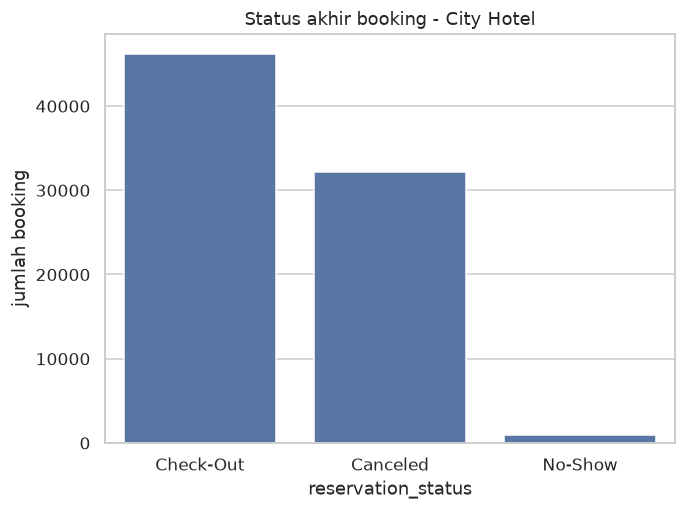

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat; isinya hanya bergantung pada data, bukan pada hasil model.*


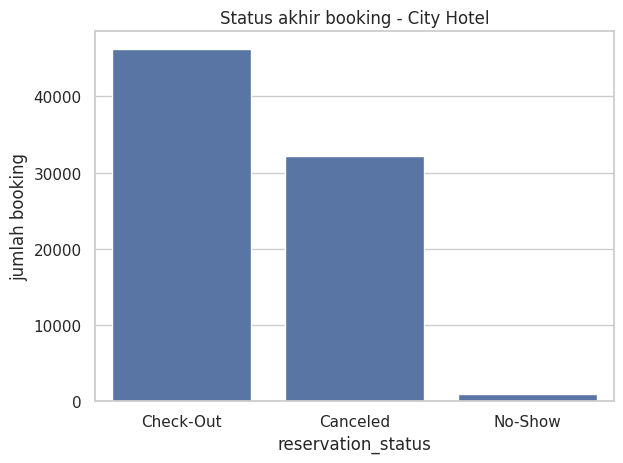

In [ ]:
## Visual: jumlah booking per status akhir
# 1. Impor alat gambar dan terapkan tema.
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='whitegrid')

# 2. Gambar jumlah booking per status akhir.
sns.countplot(data=city, x='reservation_status', color='#4C72B0')
plt.title('Status akhir booking - City Hotel')
plt.ylabel('jumlah booking')
plt.tight_layout()
plt.show()




**Pratinjau (terlihat tanpa menjalankan apa pun):**

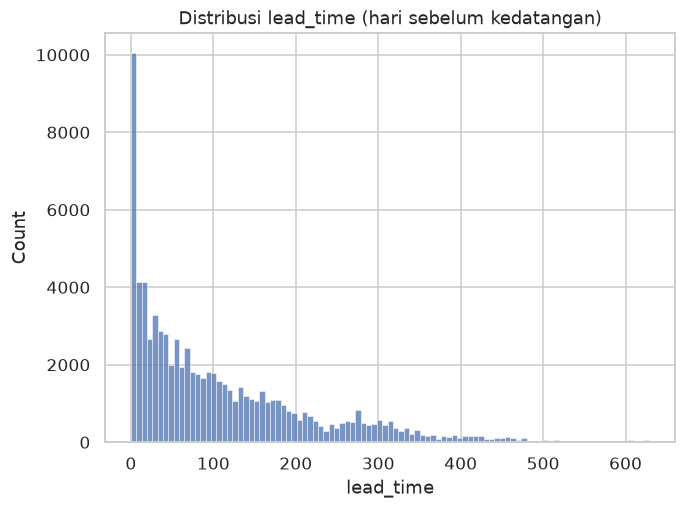

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat; isinya hanya bergantung pada data, bukan pada hasil model.*


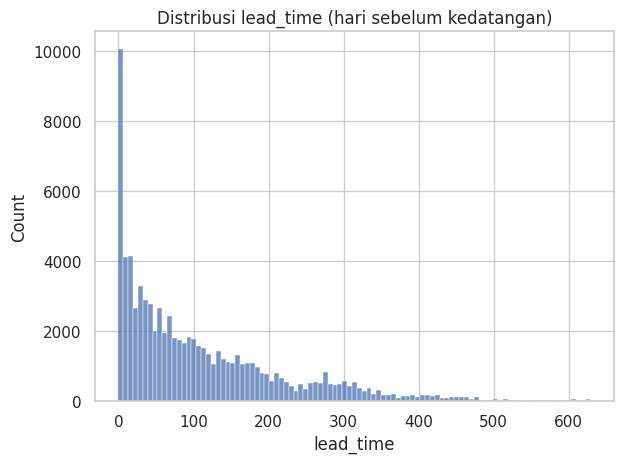

In [ ]:
## Visual: distribusi lead_time
# 1. Gambar histogram lead_time (hari antara pemesanan dan kedatangan).
sns.histplot(data=city, x='lead_time', color='#4C72B0')
plt.title('Distribusi lead_time (hari sebelum kedatangan)')
plt.tight_layout()
plt.show()




**Pratinjau (terlihat tanpa menjalankan apa pun):**

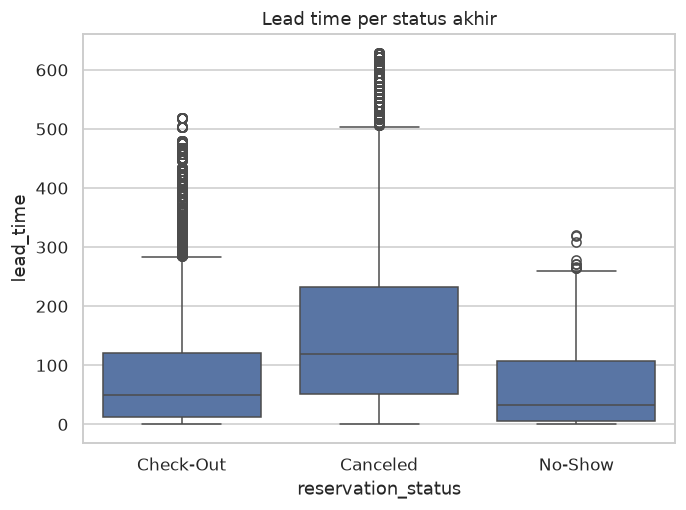

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat; isinya hanya bergantung pada data, bukan pada hasil model.*


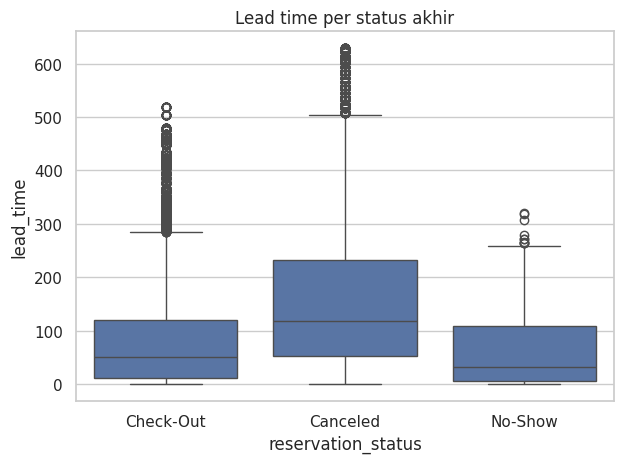

In [ ]:
## Visual: lead_time menurut status akhir
# 1. Gambar boxplot lead_time per status akhir, urut Check-Out, Canceled, No-Show.
sns.boxplot(data=city, x='reservation_status', y='lead_time',
            order=['Check-Out', 'Canceled', 'No-Show'])
plt.title('Lead time per status akhir')
plt.tight_layout()
plt.show()




**Pratinjau (terlihat tanpa menjalankan apa pun):**

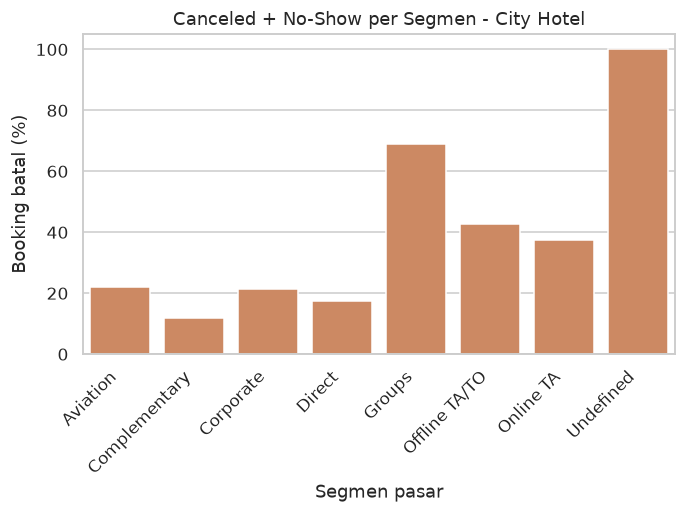

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat; isinya hanya bergantung pada data, bukan pada hasil model.*


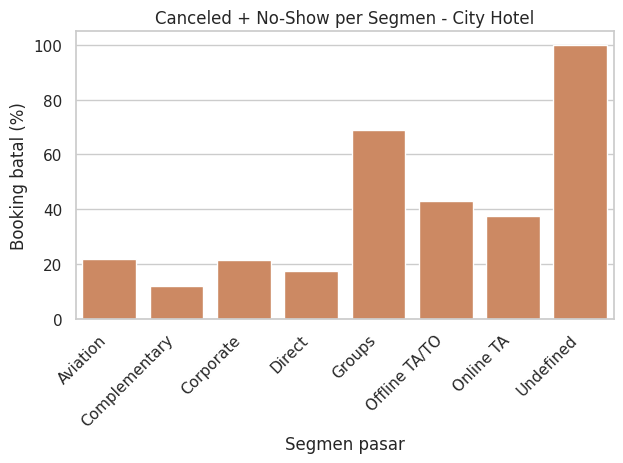

In [ ]:
## Visual: persentase pembatalan per segmen (versi pandas)
# Tujuan: mengulang hitungan SQL tadi dengan pandas, lalu menggambarnya.

# 1. Tandai booking yang berakhir Canceled atau No-Show.
kondisi_batal = city['reservation_status'].isin(['Canceled', 'No-Show'])

# 2. Hitung persentase per segmen: jumlah batal dibagi total booking segmen.
persen_batal = city[kondisi_batal].value_counts('market_segment') / city.value_counts('market_segment') * 100

# 3. Gambar batangnya.
sns.barplot(x=persen_batal.index, y=persen_batal.values, color='#DD8452')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Booking batal (%)')
plt.xlabel('Segmen pasar')
plt.title('Canceled + No-Show per Segmen - City Hotel')
plt.tight_layout()
plt.show()


## 6. Seberapa yakin pada angka? (Sesi 6, statistik)

Satu angka dari sampel selalu punya ketidakpastian. Sesi 6 melatih cara berpikir itu; yang dipakai proyek adalah kebiasaan membaca angka sebagai rentang, bukan titik tunggal — kebiasaan yang nanti menentukan cara membaca hasil simulasi harian (Bagian 13).

**Dipakai proyek:** apakah tingginya pembatalan segmen Groups (68,86% di Bagian 4) stabil dari waktu ke waktu, atau hanya kebetulan satu-dua bulan? Sel di bawah menghitung persentase batal Groups per bulan kedatangan.

In [ ]:
## Tren pembatalan bulanan segmen Groups
# Tujuan: memeriksa apakah tingginya pembatalan Groups stabil dari waktu ke waktu.

# 1. Ambil subset segmen Groups dan bentuk periode bulan kedatangan.
groups = city[city['market_segment'] == 'Groups'].copy()
teks_periode = groups['arrival_date_year'].astype(str) + '-' + groups['arrival_date_month']
groups['periode_kedatangan'] = pd.to_datetime(teks_periode, format='%Y-%B').dt.to_period('M')

# 2. Tandai booking yang berakhir batal/no-show.
groups['batal_flag'] = groups['reservation_status'].isin(['Canceled', 'No-Show'])

# 3. Agregasi per bulan: jumlah booking, jumlah batal, dan persentasenya.
ringkasan_groups = groups.groupby('periode_kedatangan', sort=True).agg(
    jumlah_booking=('batal_flag', 'size'), jumlah_batal=('batal_flag', 'sum'))
ringkasan_groups['persen_batal'] = 100.0 * ringkasan_groups['jumlah_batal'] / ringkasan_groups['jumlah_booking']

# 4. Tampilkan beberapa bulan pertama dan rentang persentase sepanjang periode.
#    Pakai round(float(...), 1) bawaan Python: aman di semua versi pandas
#    (.min() bisa mengembalikan float Python di sebagian versi, yang tidak punya .round()).
print(ringkasan_groups.head(8).to_string())
print('...')
print('Rentang persen batal bulanan:', round(float(ringkasan_groups['persen_batal'].min()), 1), '-', round(float(ringkasan_groups['persen_batal'].max()), 1))


                    jumlah_booking  jumlah_batal  persen_batal
periode_kedatangan                                            
2015-07                        913           673     73.713034
2015-08                       1126           827     73.445826
2015-09                       1356           893     65.855457
2015-10                        964           612     63.485477
2015-11                        392           123     31.377551
2015-12                        198           123     62.121212
2016-01                        161           133     82.608696
2016-02                        224           184     82.142857
...
Rentang persen batal bulanan: 20.5 - 99.2


## 7. Kohort H-1 dan pembagian waktu

**Kohort** dibangun dari tanggal-tanggal berikut:
- `arrival_date` — tanggal kedatangan, disusun dari kolom tahun-bulan-tanggal.
- `h_minus_1` — satu hari sebelum kedatangan (hari penilaian).
- `booking_date_est` — perkiraan tanggal pembuatan booking = `arrival_date − lead_time` (rekonstruksi kita, bukan kolom asli).
- `status_date` — tanggal status terakhir booking (`reservation_status_date`).

Booking masuk kohort bila `booking_date_est < h_minus_1` **dan** belum tercatat batal sampai `h_minus_1`. Hasilnya: **42.859 booking** dengan **1.099 positif** (784 No-Show + 315 Canceled, sekitar 2,56%).

**Pembagian waktu (bukan acak), mengikuti kapan informasi tersedia:**
- **train** (27.697 booking, 790 positif): `status_date < 31 Des 2016`.
- **validation** (6.257 booking, 156 positif): `h_minus_1` antara 31 Des 2016 – 29 Apr 2017 **dan** `status_date < 30 Apr 2017` — dipakai memilih model dan simulasi harian.
- **test** (8.399 booking, 150 positif): `h_minus_1 >= 30 Apr 2017`.
- **506 booking disisihkan** (238 + 268). Yang 268 adalah baris validation-periode yang `status_date`-nya jatuh pada/ setelah 30 Apr 2017 — pembatasan tepi jendela, bukan satu periode utuh yang dibuang. 3 positif kohort ada di baris-baris yang disisihkan ini.

**Status penting test:** test **sudah pernah dievaluasi** sekali di tengah proyek (AP kandidat D = 0,0230), jadi tidak ada lagi test yang "perawan". Semua eksperimen setelah itu bersifat eksploratoris, dan membagi ulang data tidak mengembalikan test yang independen.

In [ ]:
## Bangun kohort H-1
# Tujuan: memilih booking yang dinilai pada H-1 sesuai kriteria Bagian 7.
# 1. Susun tanggal kedatangan, hari penilaian (H-1), dan perkiraan tanggal pembuatan
booking_h1 = city.copy()
booking_h1['arrival_date'] = pd.to_datetime(
    booking_h1['arrival_date_year'].astype(str) + '-'
    + booking_h1['arrival_date_month'] + '-'
    + booking_h1['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')
booking_h1['h_minus_1'] = booking_h1['arrival_date'] - pd.Timedelta(days=1)
booking_h1['booking_date_est'] = booking_h1['arrival_date'] - pd.to_timedelta(booking_h1['lead_time'], unit='D')
booking_h1['status_date'] = pd.to_datetime(booking_h1['reservation_status_date'], format='%Y-%m-%d')

# 2. Kriteria kohort: dibuat sebelum H-1 DAN belum batal sampai H-1
dibuat_sebelum_h1 = booking_h1['booking_date_est'] < booking_h1['h_minus_1']
batal_sampai_h1 = (
    (booking_h1['reservation_status'] == 'Canceled')
    & (booking_h1['status_date'] <= booking_h1['h_minus_1']))
booking_h1 = booking_h1[dibuat_sebelum_h1 & ~batal_sampai_h1].copy()

# 3. Fitur turunan: hari kedatangan dalam pekan (0 = Senin)
booking_h1['arrival_day_of_week'] = booking_h1['arrival_date'].dt.day_of_week

# 4. Jangkar yang sudah diverifikasi pada rantai asli
assert len(booking_h1) == 42859, 'ukuran kohort tidak sesuai catatan'
assert int(booking_h1['is_canceled'].sum()) == 1099, 'total positif kohort tidak sesuai catatan'
print('kohort H-1:', booking_h1.shape, '| positif:', int(booking_h1['is_canceled'].sum()))

kohort H-1: (42859, 37) | positif: 1099


In [ ]:
## Pembagian waktu: train, validation, test
# Tujuan: memisahkan tiga kelompok berdasarkan kapan informasi tersedia (bukan acak).
# 1. Masking sesuai aturan di Bagian 7
mask_train = booking_h1['status_date'] < '2016-12-31'
mask_val = (
    (booking_h1['h_minus_1'] >= '2016-12-31')
    & (booking_h1['h_minus_1'] <= '2017-04-29')
    & (booking_h1['status_date'] < '2017-04-30'))
mask_test = booking_h1['h_minus_1'] >= '2017-04-30'

train = booking_h1[mask_train].copy()
validasi = booking_h1[mask_val].copy()
test = booking_h1[mask_test].copy()

# 2. Audit: jangkar ukuran, tanpa tumpang tindih, sisa yang disisihkan
assert len(train) == 27697 and int(train['is_canceled'].sum()) == 790
assert len(validasi) == 6257 and int(validasi['is_canceled'].sum()) == 156
assert len(test) == 8399 and int(test['is_canceled'].sum()) == 150
assert len(train.index.intersection(validasi.index)) == 0
assert len(train.index.intersection(test.index)) == 0
assert len(validasi.index.intersection(test.index)) == 0
print('train:', len(train), '| validation:', len(validasi), '| test:', len(test),
      '| disisihkan:', len(booking_h1) - len(train) - len(validasi) - len(test))

train: 27697 | validation: 6257 | test: 8399 | disisihkan: 506


### Visual: dari dataset ke pembagian waktu

**Pratinjau (terlihat tanpa menjalankan apa pun):**

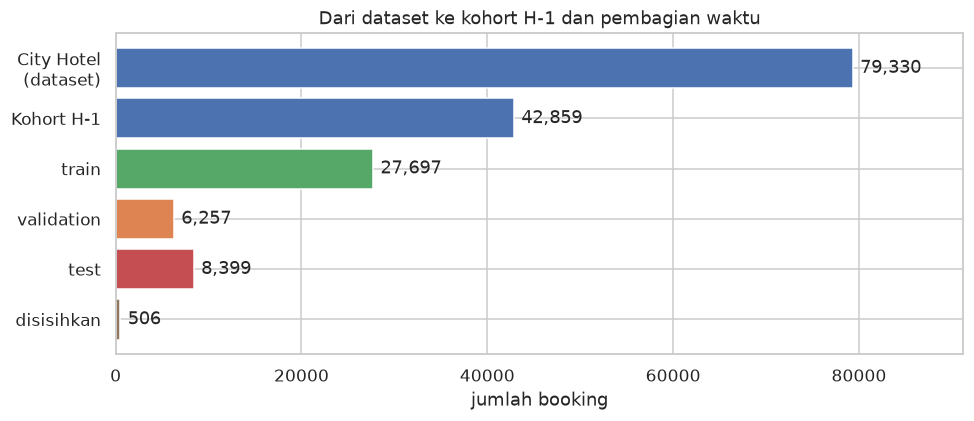

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat; isinya hanya bergantung pada data, bukan pada hasil model.*


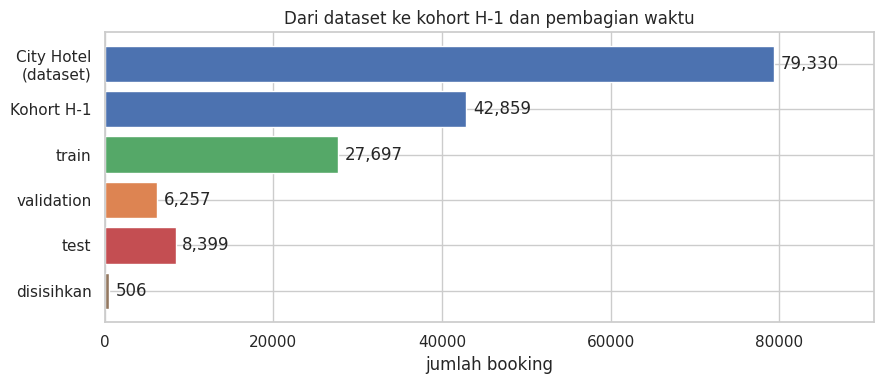

In [ ]:
## Visual: dari 79.330 booking menjadi tiga kelompok waktu
# 1. Impor alat gambar dan terapkan tema.
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

# 2. Siapkan enam tingkatan jumlah baris: dataset, kohort, tiga kelompok waktu, dan yang disisihkan.
nama = ['City Hotel\n(dataset)', 'Kohort H-1', 'train', 'validation', 'test', 'disisihkan']
jumlah = [len(city), len(booking_h1), len(train), len(validasi), len(test),
          len(booking_h1) - len(train) - len(validasi) - len(test)]
warna = ['#4C72B0', '#4C72B0', '#55A868', '#DD8452', '#C44E52', '#937860']

# 3. Gambar batang horizontal dengan label jumlah persis di ujung tiap batang.
fig, ax = plt.subplots(figsize=(9, 4))
bar = ax.barh(nama[::-1], jumlah[::-1], color=warna[::-1])
for b, j in zip(bar, jumlah[::-1]):
    ax.text(b.get_width() + 800, b.get_y() + b.get_height() / 2, format(j, ','), va='center')
ax.set_xlabel('jumlah booking')
ax.set_title('Dari dataset ke kohort H-1 dan pembagian waktu')
ax.set_xlim(0, max(jumlah) * 1.15)
plt.tight_layout()
plt.show()


In [ ]:
## Pasang CatBoost (aman diulang; cepat jika sudah terpasang)
# 1. Pasang versi persis tercatat, konsisten dengan sel penyetelan versi di Bagian 2.
%pip install -q catboost==1.2.10


## 8. Baseline S9: model awal dan evolusi metrik

**Catatan preprocessing dulu:** preprocessing hanya boleh `fit` di train — kalau ikut melihat validation/test, informasinya bocor. Kategori baru di validation yang tidak ada di train diabaikan (`handle_unknown='ignore'`) supaya tidak error; semua langkah dibungkus `Pipeline` supaya urutannya tidak salah.

Model awal ("**model baseline S9**") memakai **4 fitur** yang tersedia pada H-1: `lead_time`, `arrival_date_month`, `arrival_day_of_week` (turunan), `reserved_room_type`.

**Empat model dibandingkan:** tebak mayoritas (model patokan sederhana), Logistic Regression, XGBoost, dan CatBoost (pengaturan bawaan).

**Evolusi metrik — bagian dari perjalanan:** sesi baseline awalnya menilai dengan accuracy, precision, recall, dan F1 untuk kelas batal. Hasilnya membuka mata:

| Model | Accuracy validation | Recall batal validation | ROC-AUC validation |
|---|---|---|---|
| Tebak mayoritas | 0,9751 | 0,0000 | 0,5000 |
| Logistic Regression | 0,9751 | 0,0000 | 0,5694 |
| XGBoost | 0,9732 | 0,0128 | 0,6837 |
| CatBoost | 0,9736 | 0,0064 | 0,6331 |

Akurasi 97,5% ternyata bisa dicapai dengan menjawab "tidak batal" untuk semua booking — recall-nya 0. Bahkan XGBoost dan CatBoost pada ambang bawaan 0,5 nyaris tidak menandai apa pun (recall 0,013 dan 0,006). Akurasi dan ambang bawaan **menyesatkan** untuk data setimpang ini (2,5% positif). Sejak itu penilaian bergeser ke metrik berbasis **urutan skor**: ROC-AUC, lalu **Average Precision (AP)** sebagai metrik utama, karena skenario operasionalnya berbentuk "periksa K teratas dari daftar urut" — AP merangkum kualitas urutan untuk kelas positif yang langka.

**Hasil tercatat** (sesi evaluasi; yang lain dihitung ulang oleh sel di bawah):

| Model | AP validation |
|---|---|
| Patokan peringkat acak (= prevalensi positif; sama dengan AP model tebak mayoritas) | ≈ 0,0249 |
| Logistic Regression | 0.029472401738803444 |
| XGBoost 4 fitur (baseline S9) | 0.0939806541915978 |
| CatBoost 4 fitur | 0,0438 (dibulatkan 4 digit) |

Bacaan: baseline S9 mengurutkan lebih baik dari acak, tetapi jauh dari kuat.

**Pratinjau (terlihat tanpa menjalankan apa pun):**

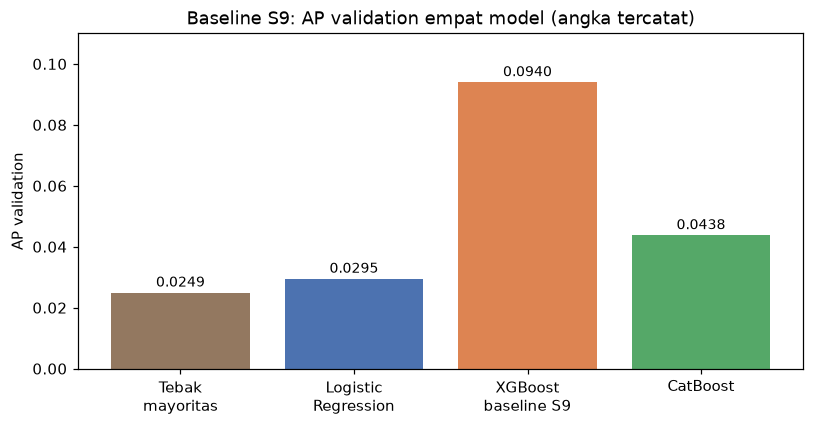

*Direkonstruksi langsung dari tabel tercatat pada bagian ini (bukan hasil menjalankan ulang); nilai persisnya ada pada tabel.*


In [ ]:
## Baseline S9: empat model pada 4 fitur awal
# Tujuan: membangun patokan pertama dan menilai urutan skornya dengan AP.
# 1. Fitur awal: 4 kolom yang tersedia pada H-1
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).
fitur_awal = ['lead_time', 'arrival_date_month', 'arrival_day_of_week', 'reserved_room_type']
X_train, y_train = train[fitur_awal].copy(), train['is_canceled'].copy()
X_val, y_val = validasi[fitur_awal].copy(), validasi['is_canceled'].copy()

# 2. Preprocessing: one-hot untuk kategori, numerik diteruskan
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

kolom_kategori = ['arrival_date_month', 'arrival_day_of_week', 'reserved_room_type']
kolom_numerik = ['lead_time']

# 3. Empat model
model_mayoritas = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
model_lr = Pipeline([
    ('preprocessing', ColumnTransformer([
        ('kategori', OneHotEncoder(handle_unknown='ignore'), kolom_kategori),
        ('numerik', StandardScaler(), kolom_numerik)])),
    ('model', LogisticRegression(max_iter=5000, random_state=42))]).fit(X_train, y_train)
model_xgb = Pipeline([
    ('preprocessing', ColumnTransformer([
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kolom_kategori),
        ('numerik', 'passthrough', kolom_numerik)])),
    ('model', XGBClassifier(random_state=42))]).fit(X_train, y_train)
X_train_cb, X_val_cb = X_train.copy(), X_val.copy()
for kolom in kolom_kategori:
    X_train_cb[kolom] = X_train_cb[kolom].astype(str)
    X_val_cb[kolom] = X_val_cb[kolom].astype(str)
model_cb = CatBoostClassifier(cat_features=kolom_kategori, random_state=42, verbose=False)
model_cb.fit(X_train_cb, y_train)

# 4. AP validation per model (kolom skor kelas positif dibaca dari classes_)
def skor_positif(model, X):
    proba = model.predict_proba(X)
    return proba[:, list(model.classes_).index(1)]

for nama, model in [('tebak mayoritas', model_mayoritas), ('Logistic Regression', model_lr), ('XGBoost baseline S9', model_xgb)]:
    print('AP validation', nama, ':', average_precision_score(y_val, skor_positif(model, X_val)))
skor_val_cb_awal = model_cb.predict_proba(X_val_cb)[:, list(model_cb.classes_).index(1)]
print('AP validation CatBoost :', average_precision_score(y_val, skor_val_cb_awal))

AP validation tebak mayoritas : 0.02493207607479623
AP validation Logistic Regression : 0.029472401738803444
AP validation XGBoost baseline S9 : 0.0939806541915978
AP validation CatBoost : 0.04377450496759701


### Visual: kurva Precision-Recall baseline
Patokan acak = garis putus-putus pada prevalensi validation (156/6257 ≈ 0,0249). Nilai AP di legenda dibulatkan 4 digit hanya untuk tampilan; angka penuh ada di tabel hasil tercatat.

**Pratinjau (terlihat tanpa menjalankan apa pun):**

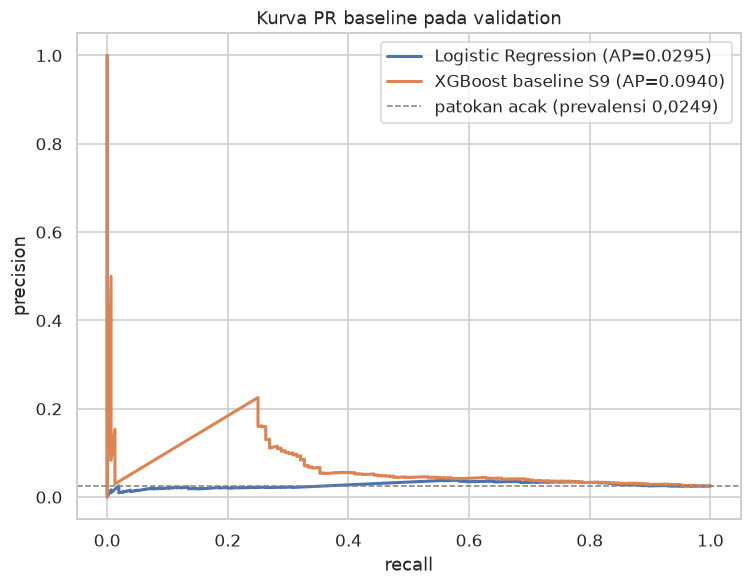

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat (scikit-learn 1.6.1, XGBoost 3.4.1, CatBoost 1.2.10); pada versi terpin angka dan kurva sama persis dengan sesi tercatat.*


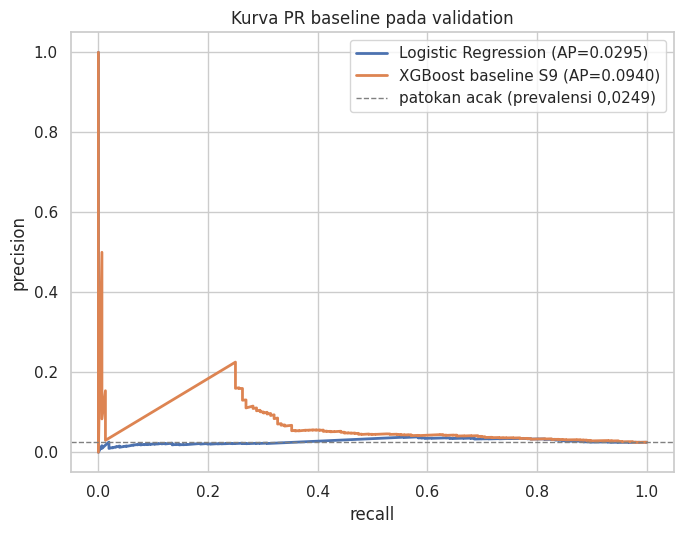

In [ ]:
## Visual: kurva Precision-Recall baseline pada validation
# Hasil run ulang: pada versi terpin kurva dan angkanya sama persis dengan sesi tercatat
# (AP kedua model cocok bit-for-bit, sudah diverifikasi ujung-ke-ujung).

# 1. Impor alat kurva precision-recall.
from sklearn.metrics import precision_recall_curve

# 2. Gambar kurva PR untuk Logistic Regression dan XGBoost baseline pada validation.
plt.figure(figsize=(7, 5.5))
for nama, model, warna in [('Logistic Regression', model_lr, '#4C72B0'), ('XGBoost baseline S9', model_xgb, '#DD8452')]:
    presisi_kurva, rec_kurva, ambang_kurva = precision_recall_curve(y_val, skor_positif(model, X_val))
    ap_kurva = average_precision_score(y_val, skor_positif(model, X_val))
    plt.plot(rec_kurva, presisi_kurva, color=warna, lw=2, label='{} (AP={:.4f})'.format(nama, ap_kurva))

# 3. Tambahkan patokan acak (prevalensi positif validation) dan hiasan.
plt.axhline(156 / 6257, color='gray', ls='--', lw=1, label='patokan acak (prevalensi 0,0249)')
plt.xlabel('recall')
plt.ylabel('precision')
plt.title('Kurva PR baseline pada validation')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 9. Fold waktu, tuning pertama, dan membaca threshold (Sesi 10)

**Fold waktu:** train dibagi 3 fold kronologis — latih di periode awal, uji di periode berikutnya, dengan penjaga H-1 (label uji belum boleh tersedia saat latih). Tuning pertama memakai GridSearchCV di atas fold ini (XGBoost: kedalaman × pasangan learning rate–jumlah pohon; LR: regularisasi; CatBoost: kedalaman × learning rate).

**Hasil tercatat — dan temuan negatifnya:**

| Kandidat | AP validation | ROC-AUC validation |
|---|---|---|
| XGBoost - awal S9 | 0,0940 | 0,6837 |
| XGBoost - hasil tuning | 0,0493 | 0,6649 |
| LR - awal S9 | 0,0295 | 0,5694 |
| LR - hasil tuning | 0,0271 | 0,5357 |
| CatBoost - awal S9 | 0,0438 | 0,6331 |
| CatBoost - hasil tuning | 0,0426 | 0,6275 |

Tuning dengan CV waktu justru **menurunkan** hasil validation untuk ketiga keluarga — pemenang di fold train bukan pemenang di periode berikutnya. Inilah sinyal pertama bahwa generalisasi lintas waktu adalah masalah utama proyek (diperdalam di Bagian 11).

**Membaca threshold:** dari kurva precision–recall, satu aturan batas skor dipilih di sekitar recall 45% dan diubah menjadi jumlah booking nyata. **Hasil tercatat** (baseline simulasi yang disepakati, XGBoost awal S9): threshold presisi penuh `0.054934270679950714` → 1.395 booking ditandai, 70 pembatalan tertangkap (TP), 1.325 alarm palsu (FP), 86 terlewat (FN) dari 156. Statusnya: baseline simulasi, **bukan SOP hotel**.

Sel berikut mengulang cara membaca threshold itu dari skor validation.

**Pratinjau (terlihat tanpa menjalankan apa pun):**

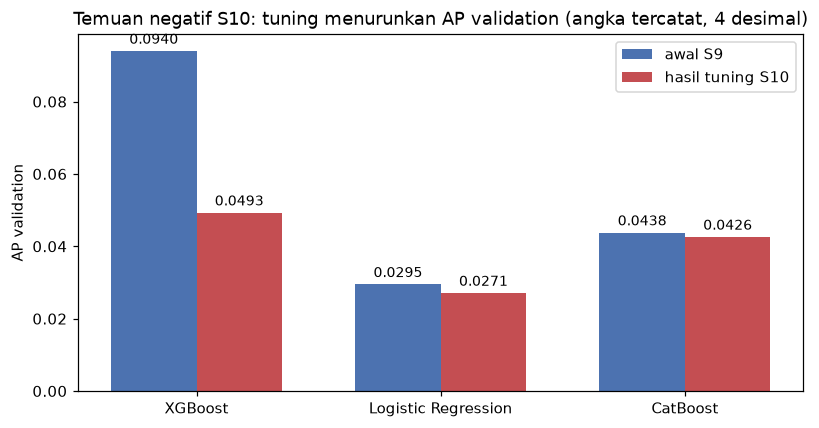

*Direkonstruksi langsung dari tabel tercatat pada bagian ini (bukan hasil menjalankan ulang); nilai persisnya ada pada tabel.*


In [ ]:
## Dari kurva precision-recall ke aturan batas skor
# Tujuan: mengulang cara S10 membaca threshold - pilih aturan di sekitar
# recall 45%, lalu hitung berapa booking yang benar-benar ditandai.
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).
from sklearn.metrics import precision_recall_curve

# 1. Semua aturan batas dari skor validation baseline
skor_val_xgb = skor_positif(model_xgb, X_val)
presisi_kurva, rec_kurva, ambang_kurva = precision_recall_curve(y_val, skor_val_xgb)
aturan_xgb = pd.DataFrame({'threshold': ambang_kurva, 'precision': presisi_kurva[:-1], 'recall': rec_kurva[:-1]})

# 2. Pilih aturan di sekitar recall 45%
aturan_sekitar_45 = aturan_xgb[(aturan_xgb['recall'] >= 0.35) & (aturan_xgb['recall'] <= 0.45)]
print('Jumlah aturan dalam rentang:', len(aturan_sekitar_45))
print(aturan_sekitar_45.head(3).to_string())

# 3. Terapkan aturan pertama: hitung yang ditandai, tertangkap, alarm palsu, terlewat
batas = aturan_sekitar_45.iloc[0]['threshold']
ditandai = skor_val_xgb >= batas
label_val = y_val.to_numpy()
print()
print('Batas skor contoh   :', batas)
print('Booking ditandai    :', int(ditandai.sum()), 'dari', len(label_val))
print('Benar batal (TP)    :', int((ditandai & (label_val == 1)).sum()))
print('Alarm palsu (FP)    :', int((ditandai & (label_val == 0)).sum()))
print('Terlewat (FN)       :', int((~ditandai & (label_val == 1)).sum()))

Jumlah aturan dalam rentang: 300
      threshold  precision    recall
2110   0.052614   0.047912  0.448718
2111   0.052754   0.048011  0.448718
2112   0.052812   0.048077  0.448718

Batas skor contoh   : 0.05261412635445595
Booking ditandai    : 1461 dari 6257
Benar batal (TP)    : 70
Alarm palsu (FP)    : 1391
Terlewat (FN)       : 86


## 10. Eksperimen fitur A–E (hasil tercatat)

Lima resep fitur dibandingkan dengan baseline S9, dinilai AP di validation. **Arsip** — puluhan pelatihannya tidak diulang di notebook ini:

| Resep | Isi | AP validation |
|---|---|---|
| A | 4 fitur dasar (= baseline S9) | 0.0939806541915978 |
| B | A + `market_segment` | **ditolak** (tidak membaik) |
| C | A + 3 fitur riwayat | 0.1097760125204123 |
| D | C + 5 karakteristik booking (**12 fitur**) | 0.10815288295901797 |
| E | C + `stays_in_week_nights` | 0.10358667602509217 |

**12 fitur D** — kategori: `arrival_date_month`, `arrival_day_of_week`, `reserved_room_type`, `customer_type`, `distribution_channel`; numerik: `lead_time`, `previous_cancellations`, `previous_bookings_not_canceled`, `is_repeated_guest`, `total_of_special_requests`, `stays_in_weekend_nights`, `stays_in_week_nights`.

**Status D:** kandidat **historis/deskriptif** yang dipilih secara retrospektif — bukan "model final" dan tidak terbukti unggul (C lebih tinggi di validation). Validation dan test sudah pernah dilihat selama proses, jadi semua angka di tabel ini bersifat eksploratoris.

**Pratinjau (terlihat tanpa menjalankan apa pun):**

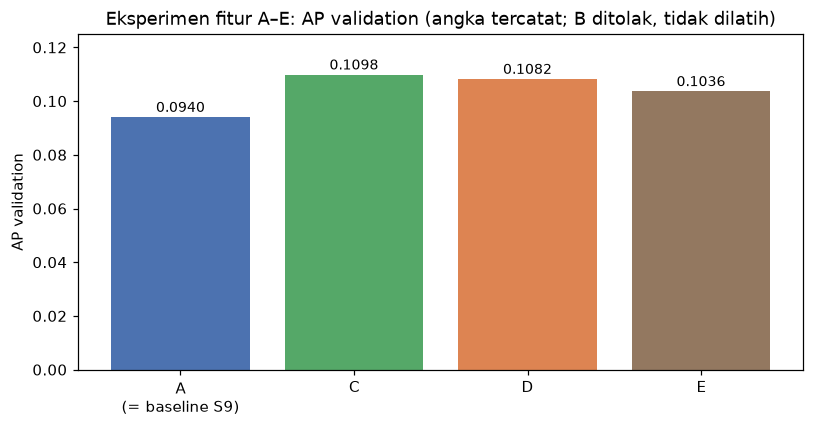

*Direkonstruksi langsung dari tabel tercatat pada bagian ini (bukan hasil menjalankan ulang); nilai persisnya ada pada tabel.*


## 11. Diagnosis: generalisasi model lemah

Masalah utama proyek ini terukur di kandidat D:

| Ukuran | AP |
|---|---|
| train | 0.6653759620611807 |
| validation | 0.10815288295901797 |
| test | 0.023029135706374496 |
| fold temporal dalam train (3 fold, dibulatkan 6 digit) | 0.056623 / 0.033999 / 0.071347 |

**Batas makna:** angka-angka ini menunjukkan generalisasi lintas waktu yang lemah *dalam pengukuran kita*. Mereka tidak menutup kemungkinan overfitting maupun penyebab lain, dan **penyebab utamanya belum terbukti**. AP train memang optimistis oleh konstruksi (data yang sama dipakai melatih), jadi celah train–validation tidak bisa dibaca sebagai satu sebab tunggal.

Sel di bawah menghitung ulang celah train–validation untuk baseline 4 fitur, supaya polanya terlihat langsung.

In [ ]:
## Diagnosis: celah train vs validation pada baseline
# Tujuan: melihat pola yang sama pada baseline S9 (bukan hanya kandidat D).
# Catatan: AP train bersifat in-sample dan optimistis oleh konstruksi.
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat.

# 1. Skor train dan validation dengan model baseline yang sama.
skor_train_xgb = skor_positif(model_xgb, X_train)
skor_val_xgb = skor_positif(model_xgb, X_val)

# 2. Hitung AP keduanya dan tampilkan celahnya.
ap_train = average_precision_score(y_train, skor_train_xgb)
ap_val = average_precision_score(y_val, skor_val_xgb)
print('AP train      :', ap_train)
print('AP validation :', ap_val)
print('celah         :', ap_train - ap_val)


AP train      : 0.3881886198086437
AP validation : 0.0939806541915978
celah         : 0.29420796561704593


### Eksperimen terkontrol: memangkas kedalaman pohon

Satu faktor diubah: resep D (12 fitur) dilatih ulang apa adanya, hanya `max_depth` diganti dari bawaan (6) menjadi 3.

**Hasil tercatat** (kandidat D, laptop): AP train 0,6654 → 0,3459; AP validation 0,1082 → 0,0884; celah 0,5572 → 0,2574.

**Kesimpulan terbatas:** celah menyusut, tetapi karena performa train ikut turun — hasil validation *tidak membaik*. Hipotesis "membatasi kedalaman memperbaiki generalisasi di setting ini" tidak didukung. Ini bukan bukti soal penyebab.

In [ ]:
## Eksperimen terkontrol: clone pipeline D asli, hanya max_depth diubah
# Tujuan: mengulang eksperimen satu faktor dari laptop - pipeline D ASLI disalin
# persis (urutan fitur, preprocessing, parameter bawaan), HANYA max_depth 6 -> 3.
# Angka yang mengikat adalah hasil tercatat di laptop (teks di atas).
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).

# 1. Fitur D dalam URUTAN ASLI (lead_time dulu, sesuai pipeline tersimpan)
fitur_d = ['lead_time', 'arrival_date_month', 'arrival_day_of_week', 'reserved_room_type',
           'previous_cancellations', 'previous_bookings_not_canceled', 'is_repeated_guest',
           'customer_type', 'distribution_channel', 'total_of_special_requests',
           'stays_in_weekend_nights', 'stays_in_week_nights']
kategori_d = ['arrival_date_month', 'arrival_day_of_week', 'reserved_room_type',
              'customer_type', 'distribution_channel']
passthrough_d = ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled',
                 'is_repeated_guest', 'total_of_special_requests',
                 'stays_in_weekend_nights', 'stays_in_week_nights']

# 2. Preprocessor D asli: one-hot kategori + numerik passthrough (tanpa enable_categorical)
for kedalaman in [6, 3]:
    demo_d = Pipeline([
        ('preprocessing', ColumnTransformer([
            ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kategori_d),
            ('durasi', 'passthrough', passthrough_d)])),
        ('model', XGBClassifier(random_state=42, max_depth=kedalaman))])
    demo_d.fit(train[fitur_d], y_train)
    ap_tr = average_precision_score(y_train, skor_positif(demo_d, train[fitur_d]))
    ap_va = average_precision_score(y_val, skor_positif(demo_d, validasi[fitur_d]))
    print(f'max_depth={kedalaman} | AP train: {ap_tr} | AP validation: {ap_va} | celah: {ap_tr - ap_va}')

max_depth=6 | AP train: 0.6653759620611807 | AP validation: 0.10815288295901797 | celah: 0.5572230791021627
max_depth=3 | AP train: 0.345880057373502 | AP validation: 0.08843284455504583 | celah: 0.2574472128184562


## 12. Tuning tiga keluarga model (hasil tercatat) + melatih pemenangnya

**Desain yang disepakati dulu:** 13 kandidat (3 LR + 6 XGBoost + 4 CatBoost) × 3 fold waktu di dalam train = 39 pelatihan; preprocessing di dalam fold; metrik AP; pemenang tiap keluarga = rata-rata AP uji fold tertinggi; lalu **satu** evaluasi validation per keluarga. Fold waktu: latih di periode awal, uji di periode berikutnya, dengan penjaga H-1 agar informasi uji tidak bocor ke latih.

**Hasil tercatat** (sesi evaluasi 19–20 Nov; grid tidak diulang di notebook ini):

| Keluarga | Pemenang | AP validation |
|---|---|---|
| Logistic Regression | C=0.01 | 0.029324521743662055 |
| XGBoost | max_depth=3, eta=0.3, 100 pohon | 0.08843284455504583 |
| CatBoost | depth=6, learning_rate=0.03 | 0.06599095899782473 |

Ketiganya dilatih pada **12 fitur D** di atas. Pemenang XGBoost memakai **fitur D yang sama** dengan konfigurasi model `max_depth=3, eta=0.3, 100 pohon` — nilai yang sama dengan eksperimen terkontrol Bagian 11 — tetapi preprocessing dan urutan kolomnya **berbeda** dari pipeline D asli (enable_categorical, kategori dulu). Keduanya objek dan proses yang berbeda; AP validation-nya kebetulan **sama jika dibulatkan** (0,0884). Ini fakta apa adanya, bukan bukti ekuivalensi resep. Karena test sudah terlihat dan validation berulang dipakai memilih, angka-angka ini **eksploratoris**, bukan janji performa.

Sel berikutnya melatih ketiga pemenang sekali di seluruh train, supaya simulasi harian (Bagian 13) bisa dijalankan.

In [ ]:
## Latih tiga pemenang tuning pada 12 fitur D
# Tujuan: menyiapkan model untuk simulasi harian. Konfigurasi persis pemenang
# dari proses tuning yang diringkas di Bagian 12 (grid-nya sendiri tidak diulang).
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).
import numpy as np
from sklearn.impute import SimpleImputer
from catboost import CatBoostClassifier

# 1. Daftar 12 fitur D
fitur_d_kategori = ['arrival_date_month', 'arrival_day_of_week', 'reserved_room_type', 'customer_type', 'distribution_channel']
fitur_d_numerik = ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled', 'is_repeated_guest', 'total_of_special_requests', 'stays_in_weekend_nights', 'stays_in_week_nights']
fitur_d = fitur_d_kategori + fitur_d_numerik

# 2. Pemenang LR: imputasi median + standardisasi numerik, C=0.01
model_menang_lr = Pipeline([
    ('preprocessing', ColumnTransformer([
        ('kategori', OneHotEncoder(handle_unknown='ignore'), fitur_d_kategori),
        ('numerik', Pipeline([('isi', SimpleImputer(strategy='median')), ('skala', StandardScaler())]), fitur_d_numerik)])),
    ('model', LogisticRegression(C=0.01, max_iter=5000, random_state=42))]).fit(train[fitur_d], y_train)

# 3. Pemenang XGBoost: kedalaman 3, eta 0.3, 100 pohon
model_menang_xgb = Pipeline([
    ('preprocessing', ColumnTransformer([
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), fitur_d_kategori)],
        remainder='passthrough')),
    ('model', XGBClassifier(enable_categorical=True, random_state=42, max_depth=3, learning_rate=0.3, n_estimators=100, n_jobs=1))]).fit(train[fitur_d], y_train)

# 4. Pemenang CatBoost: kategori sebagai teks + cat_features native
train_cb = train[fitur_d].copy()
validasi_cb = validasi[fitur_d].copy()
for kolom in fitur_d_kategori:
    train_cb[kolom] = train_cb[kolom].astype(str)
    validasi_cb[kolom] = validasi_cb[kolom].astype(str)
model_menang_cb = CatBoostClassifier(iterations=1000, depth=6, learning_rate=0.03,
                                     loss_function='Logloss', random_state=42,
                                     verbose=False, allow_writing_files=False, thread_count=1)
model_menang_cb.fit(train_cb, y_train, cat_features=fitur_d_kategori)

# 5. AP validation ketiga pemenang
skor_val_lr = skor_positif(model_menang_lr, validasi[fitur_d])
skor_val_xgb_tuned = skor_positif(model_menang_xgb, validasi[fitur_d])
skor_val_cb = model_menang_cb.predict_proba(validasi_cb)[:, list(model_menang_cb.classes_).index(1)]
print('AP validation LR      :', average_precision_score(y_val, skor_val_lr))
print('AP validation XGBoost :', average_precision_score(y_val, skor_val_xgb_tuned))
print('AP validation CatBoost:', average_precision_score(y_val, skor_val_cb))

AP validation LR      : 0.029324521743662055
AP validation XGBoost : 0.08843284455504583
AP validation CatBoost: 0.06599095899782473


## 13. Simulasi harian H-1: periksa 5 dan 10 teratas per hari

Skenario operasional yang disepakati di akhir S10 (bukan pertanyaan hari pertama) dijalankan di subset validation (118 hari penilaian, 31 Des 2016 – 27 Apr 2017):

- Setiap hari, urutkan booking hari itu menurut skor, ambil **K teratas** (K = 5 dan 10, anggaran ilustratif).
- **Metrik ditetapkan sebelum jalan:** total diperiksa, positif tertangkap dari 156, precision dan recall mikro di seluruh hari (hari tanpa batal tetap dihitung).
- **Skor seri di batas daftar** dilaporkan sebagai **rentang minimum–maksimum analitik**: anggota di atas batas pasti masuk, anggota seri berebut sisa slot. Rentang ini *bukan* interval kepercayaan dan *bukan* cara memilih berdasarkan label masa depan.
- Model **tidak dilatih ulang** di tengah simulasi; test tidak disentuh.

In [ ]:
## Simulasi harian: top-5 dan top-10 per hari untuk XGBoost dan CatBoost
# Tujuan: menilai model sesuai skenario operasional H-1 di Bagian 13.
# 1. Penjaga jangkar subset validation
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).
assert len(validasi) == 6257 and int(validasi['is_canceled'].sum()) == 156
label_harian = validasi['is_canceled'].to_numpy()
assert set(np.unique(label_harian)) <= {0, 1}, 'label bukan biner 0/1'
tanggal_harian = validasi['h_minus_1'].dt.date.to_numpy()
daftar_hari = np.unique(tanggal_harian)
assert len(daftar_hari) == 118, 'jumlah hari penilaian tidak sesuai catatan'

# 2. Simulasi satu anggaran K untuk satu vektor skor.
#    Urutan per hari: skor terbesar dulu; seri dipecahkan urutan asli (stabil).
#    Rentang seri dihitung analitik: di atas batas pasti masuk, anggota seri berebut slot.
def simulasi_harian(skor, K):
    cek = tangkap = tangkap_min = tangkap_maks = hari_seri = 0
    for hari in daftar_hari:
        pos = np.flatnonzero(tanggal_harian == hari)
        sk, lb = skor[pos], label_harian[pos]
        k_hari = min(K, len(pos))
        pilih = np.argsort(-sk, kind='stable')[:k_hari]
        cek += k_hari
        tangkap += int(lb[pilih].sum())
        batas = sk[pilih[-1]]
        di_atas, seri = sk > batas, sk == batas
        sisa_slot = k_hari - int(di_atas.sum())
        if int(seri.sum()) > sisa_slot:
            hari_seri += 1
            pos_atas, pos_seri = int(lb[di_atas].sum()), int(lb[seri].sum())
            tangkap_min += pos_atas + max(0, pos_seri - (int(seri.sum()) - sisa_slot))
            tangkap_maks += pos_atas + min(sisa_slot, pos_seri)
        else:
            tangkap_min += int(lb[pilih].sum())
            tangkap_maks += int(lb[pilih].sum())
    return cek, tangkap, tangkap_min, tangkap_maks, hari_seri

# 3. Jalankan untuk dua model dan dua anggaran, tampilkan ringkasan mikro
ringkas_harian = []
for K in [5, 10]:
    for nama, skor in [('XGBoost', skor_val_xgb_tuned), ('CatBoost', skor_val_cb)]:
        cek, tangkap, tmin, tmaks, hari_seri = simulasi_harian(np.asarray(skor, dtype=float), K)
        ringkas_harian.append({'anggaran_per_hari': K, 'model': nama, 'total_diperiksa': cek,
                               'tertangkap': tangkap, 'tertangkap_min_seri': tmin, 'tertangkap_maks_seri': tmaks,
                               'hari_dengan_seri_batas': hari_seri,
                               'precision': tangkap / cek, 'recall_dari_156': tangkap / 156})
tabel_harian = pd.DataFrame(ringkas_harian)
print(tabel_harian.to_string(index=False))

 anggaran_per_hari    model  total_diperiksa  tertangkap  tertangkap_min_seri  tertangkap_maks_seri  hari_dengan_seri_batas  precision  recall_dari_156
                 5  XGBoost              590          27                   22                    27                      12   0.045763         0.173077
                 5 CatBoost              590          26                   23                    26                      14   0.044068         0.166667
                10  XGBoost             1180          47                   35                    47                      26   0.039831         0.301282
                10 CatBoost             1180          48                   40                    48                      17   0.040678         0.307692


### Hasil tercatat simulasi (output sesi evaluasi)

| Anggaran/hari | Model | Diperiksa | Tertangkap | Rentang seri | Precision | Recall dari 156 |
|---|---|---|---|---|---|---|
| 5 | XGBoost | 590 | 27 | 22–27 | 0.04576271186440678 | 0.17307692307692307 |
| 5 | CatBoost | 590 | 26 | 23–26 | 0.04406779661016949 | 0.16666666666666666 |
| 10 | XGBoost | 1180 | 47 | 35–47 | 0.03983050847457627 | 0.30128205128205127 |
| 10 | CatBoost | 1180 | 48 | 40–48 | 0.04067796610169491 | 0.3076923076923077 |

**Cara membaca:**
- Menggandakan pemeriksaan 5 → 10 menambah sekitar 20–22 temuan, dengan precision turun. Layak atau tidak adalah keputusan operasional (biaya telepon vs nilai konfirmasi lebih awal), bukan pertanyaan model.
- Rentang seri kedua model **tumpang tindih** di kedua anggaran — **tidak ada pemenang** XGBoost vs CatBoost, dan itu bukan bukti keduanya setara secara statistik.
- Mayoritas pembatalan tetap terlewat (70–83%) dan precision rendah (±4%).

## 14. Pembanding acak: ekspektasi temuan tanpa model

Pembanding paling sederhana: kalau hotel memilih booking **secara acak setiap hari** dengan jumlah pemeriksaan yang sama, berapa pembatalan yang *diharapkan* tertangkap?

Memilih `k` booking seragam acak tanpa pengembalian dari satu hari dengan `n` booking dan `p` positif memberi ekspektasi temuan `k × p / n`. Ekspektasi dijumlahkan **per hari** (bukan dari rasio global, karena komposisi tiap hari berbeda), termasuk hari tanpa positif.

**Cara baca:** ini ekspektasi teoretis (boleh desimal), *bukan* interval kepercayaan dan *bukan* uji signifikansi — satu pilihan acak sungguhan bisa di atas atau di bawahnya.

In [ ]:
## Benchmark acak harian (analitik, tanpa pengacakan)
# Tujuan: ekspektasi temuan strategi acak dengan usaha yang sama persis.
# 1. Hitung n dan p per hari dari label validation
# Hasil run ulang: pada versi terpin angkanya cocok bit-for-bit dengan tabel tercatat (diverifikasi ujung-ke-ujung).
baris_hari = []
for hari in daftar_hari:
    pos = np.flatnonzero(tanggal_harian == hari)
    baris_hari.append({'hari': hari, 'n_booking': len(pos), 'n_positif': int(label_harian[pos].sum())})
per_hari = pd.DataFrame(baris_hari)
assert int(per_hari['n_booking'].sum()) == 6257 and int(per_hari['n_positif'].sum()) == 156

# 2. Ekspektasi temuan acak untuk anggaran 5 dan 10 per hari
ekspektasi_acak = {}
for K in [5, 10]:
    ambil = np.minimum(K, per_hari['n_booking'])
    cek = int(ambil.sum())
    harapan = float((ambil * per_hari['n_positif'] / per_hari['n_booking']).sum())
    ekspektasi_acak[K] = harapan
    print('anggaran', K, '| diperiksa:', cek, '| ekspektasi tertangkap:', harapan,
          '| precision:', harapan / cek, '| recall:', harapan / 156)

anggaran 5 | diperiksa: 590 | ekspektasi tertangkap: 13.490041370276986 | precision: 0.022864476898774553 | recall: 0.08647462416844222
anggaran 10 | diperiksa: 1180 | ekspektasi tertangkap: 26.98008274055397 | precision: 0.022864476898774553 | recall: 0.17294924833688444


### Hasil tercatat dan kesimpulan perbandingan

Ekspektasi acak tercatat: **13,49** temuan (5/hari) dan **26,98** temuan (10/hari) — persis dua kali lipat karena setiap hari punya minimal 17 booking.

| Anggaran | Ekspektasi acak | XGBoost (rentang) | CatBoost (rentang) |
|---|---|---|---|
| 5/hari | 13.490041370276986 | 27 (22–27) | 26 (23–26) |
| 10/hari | 26.98008274055397 | 47 (35–47) | 48 (40–48) |

**Kesimpulan deskriptif:** pada subset validation ini, kedua model menemukan lebih banyak positif daripada ekspektasi acak dengan usaha sama — **bahkan di ujung rentang seri paling sial** (22 dan 23 di atas 13,49; 35 dan 40 di atas 26,98). Ini perbandingan dengan rata-rata teoretis, *bukan* uji signifikansi dan *bukan* bukti mengalahkan setiap pilihan acak. Ia menjawab pertanyaan yang mengerucut menjadi skenario H-1 (Bagian 13): urutan skor model memang membawa informasi untuk prioritas harian — dengan manfaat yang terbatas.

### Visual: model vs ekspektasi acak
Batang = temuan model; garis tegak hitam = rentang akibat skor seri; garis putus biru = ekspektasi acak dengan jumlah pemeriksaan sama.

**Pratinjau (terlihat tanpa menjalankan apa pun):**

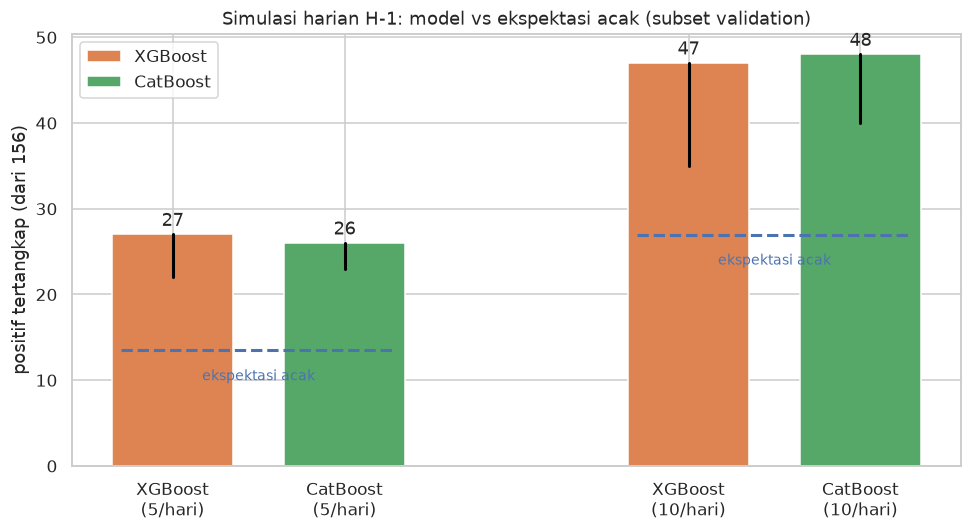

*Dihasilkan dari sel kode tepat di bawah pada lingkungan tercatat (scikit-learn 1.6.1, XGBoost 3.4.1, CatBoost 1.2.10); pada versi terpin angka dan kurva sama persis dengan sesi tercatat.*


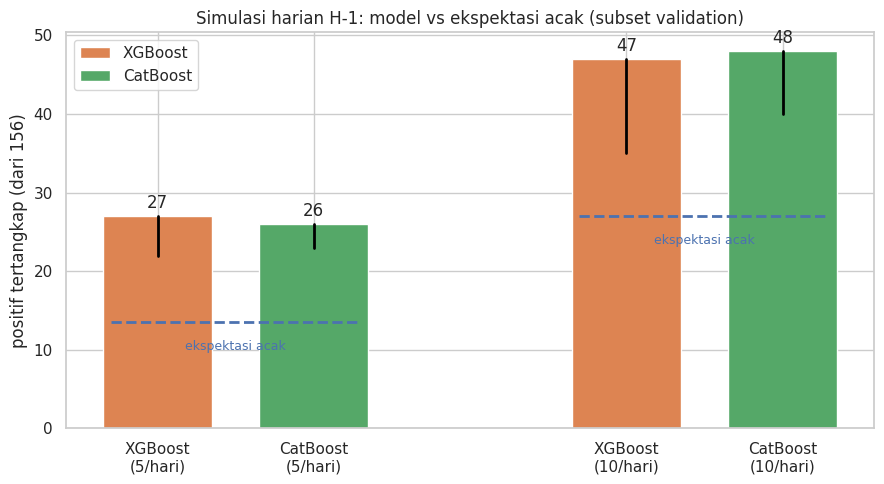

In [ ]:
## Visual: hasil simulasi harian vs ekspektasi acak
# Hasil run ulang: pada versi terpin angka simulasinya sama persis dengan tabel tercatat.

# 1. Siapkan posisi batang dan warna per model.
fig, ax = plt.subplots(figsize=(9, 5))
posisi = {'5 XGBoost': 0, '5 CatBoost': 1, '10 XGBoost': 3, '10 CatBoost': 4}
warna_model = {'XGBoost': '#DD8452', 'CatBoost': '#55A868'}

# 2. Gambar batang temuan model, dengan garis rentang akibat pilihan skor seri.
for baris in ringkas_harian:
    x = posisi[str(baris['anggaran_per_hari']) + ' ' + baris['model']]
    ax.bar(x, baris['tertangkap'], width=0.7, color=warna_model[baris['model']],
           label=baris['model'] if baris['anggaran_per_hari'] == 5 else None)
    ax.plot([x, x], [baris['tertangkap_min_seri'], baris['tertangkap_maks_seri']], color='black', lw=2)
    ax.text(x, baris['tertangkap'] + 1, str(baris['tertangkap']), ha='center')

# 3. Tambahkan garis putus ekspektasi acak dengan jumlah pemeriksaan yang sama.
for K, x_tengah in [(5, 0.5), (10, 3.5)]:
    ax.hlines(ekspektasi_acak[K], x_tengah - 0.8, x_tengah + 0.8, colors='#4C72B0', linestyles='--', lw=2)
    ax.text(x_tengah, ekspektasi_acak[K] - 3.5, 'ekspektasi acak', color='#4C72B0', ha='center', fontsize=9)

# 4. Hiasan sumbu dan judul.
ax.set_xticks([0, 1, 3, 4])
ax.set_xticklabels(['XGBoost\n(5/hari)', 'CatBoost\n(5/hari)', 'XGBoost\n(10/hari)', 'CatBoost\n(10/hari)'])
ax.set_ylabel('positif tertangkap (dari 156)')
ax.set_title('Simulasi harian H-1: model vs ekspektasi acak (subset validation)')
ax.legend()
plt.tight_layout()
plt.show()


## 15. Kesimpulan dan keterbatasan

**Yang terjawab (deskriptif, di subset validation):**
- Urutan skor model menemukan lebih banyak pembatalan daripada ekspektasi acak dengan jumlah pemeriksaan sama — tahan terhadap cara memecah skor seri.
- Generalisasi lintas waktu lemah: AP train 0,6654 vs validation 0,1082 vs test 0,0230 (kandidat D).
- Memangkas kompleksitas model (depth 6 → 3) tidak memperbaiki hasil validation.

**Yang belum terbukti:**
- **Penyebab utama** performa lemah — temuan sejauh ini deskriptif, bukan akar masalah.
- Pemenang XGBoost vs CatBoost — rentang seri tumpang tindih.
- Bahwa telepon konfirmasi *mencegah* pembatalan — metrik simulasi mengukur deteksi/prioritas, bukan sebab-akibat.
- Kesiapan pakai di hotel nyata dan generalisasi ke periode lain.

**Keterbatasan data yang tercatat:**
- 268 baris validation disisihkan karena `status_date` di luar jendela penilaian (≥ 30 Apr 2017).
- Dua fitur riwayat (`previous_cancellations`, `previous_bookings_not_canceled`): pemotongan H-1 umum di metodologi paper mencakupnya, tetapi deskripsi per-variabel tidak mengulang tanggal patokan secara harfiah — statusnya belum dipastikan sepenuhnya.
- Sensor di tepi dataset tidak diketahui.

**Pelajaran utama proyek:** model dengan skor rendah tetap bisa dievaluasi secara jujur dan berguna sebagai bahan belajar — dan bagian dari pekerjaan data scientist adalah menyatakan kapan sebuah model *belum pantas dipercaya*.

## 16. Keputusan: model yang dipakai untuk demo

**Pilihan: XGB_D asli** — pipeline kandidat D (12 fitur, XGBoost pengaturan bawaan) yang dibekukan selama proyek. Artefaknya `pipeline_xgboost_d.joblib` tersimpan utuh di laptop (awalnya disimpan sebagai `pipeline_kandidat_d.joblib`, lalu diganti nama tanpa mengubah isi; paritas muat ulang tercatat cocok). Keputusan ini tidak melatih ulang atau mengekspor model baru.

**Alasan, sesuai bukti yang ada:**

1. **Kesinambungan cerita:** D adalah kandidat yang riwayat evaluasinya paling banyak dibahas dalam proyek ini — AP train/validation/test, fold temporal, dan audit kesalahan. Demo memakai model yang sama dengan yang dibahas membuat penjelasan nyambung.
2. **Artefaknya sudah tersimpan** dan pernah dimuat ulang untuk mengskor booking contoh, jadi demo bisa dibangun tanpa menyentuh proses pelatihan lagi.
3. **Bukan karena terbukti unggul** — ini pilihan untuk demo, bukan klaim model terbaik.

**Batas yang harus dibawa:**

- Resep C lebih tinggi di validation (0,1098 vs 0,1082), dan simulasi harian **memakai pemenang tuning trio** (XGBoost depth-3 dan CatBoost), **bukan** D asli — simulasi itu juga tidak bisa membedakan keduanya karena rentang serinya tumpang tindih.
- Aplikasi demo lama yang lebih dulu berjalan adalah milik **baseline S9** (`app.py` + `preprocessor_hotel_xgb.joblib` + `model_hotel_xgb.ubj`); aplikasi demo untuk D kemudian selesai dibangun dari pasangan file hasil Bagian 17 (`app_demo_d.py` + `preprocessing_d_demo.joblib` + `model_d_demo.ubj`) dan dipublikasikan di Streamlit Community Cloud: https://hotel-booking-demo-nuublj7myce5dnatebttq8.streamlit.app/
- Demo adalah **alat untuk menjelaskan cara kerja model dan keterbatasannya**, bukan bukti bahwa modelnya siap dipakai hotel. Merapikan notebook tidak berarti memilih ulang model secara diam-diam.

---

*Sumber data dan paper ada di Bagian 2. Ringkasan naratif proyek (file teks) menyertai notebook ini sebagai bahan laporan; penjelasan keputusan yang lebih panjang akan dikembangkan di README GitHub.*

## 17. Menyiapkan model demo: D asli, direkonstruksi dan diverifikasi

Sampai sini notebook baru *menjelaskan* pilihan model; bagian ini *menyediakan modelnya* supaya bisa diunduh dan ditunjukkan.

**Apa yang dihasilkan:** file `pipeline_xgboost_d_demo.joblib` — pipeline lengkap (preprocessing + XGBoost) yang dilatih ulang di notebook ini dengan resep D asli pada data train saja. Karena preprocessing ikut tersimpan, aplikasi demo cukup mengirim 12 kolom mentah.

**Kenapa pelatihan ulang, bukan file laptop?** Artefak asli `pipeline_xgboost_d.joblib` tetap utuh di laptop sebagai arsip historis; tidak ada yang diganti diam-diam. Yang diunduh dari sini adalah **rekonstruksi terverifikasi**: resep sama, data latih sama, dan wajib lolos dua gerbang. Gerbang 1 (sebelum file dibuat): AP train dan AP validation harus persis angka tercatat — 0,6653759620611807 dan 0,10815288295901797. Gerbang 2 (sesudah file dibuat): file dimuat ulang dan seluruh skor validation-nya dibandingkan dengan model di memori; bila beda, file dihapus. Yang *tidak* bisa diverifikasi di sini: vektor 6.257 skor historis laptop (tidak pernah tersimpan sebagai catatan), jadi dua metrik tercatat itulah pembanding yang tersedia. Kecocokan metrik adalah bukti reproduksi, bukan bukti identitas objek — identitas resep datang dari kode sumber sesi aslinya.

**Batas yang sama tetap berlaku:** ini model untuk *demo dan cerita*, bukan model yang terbukti layak operasional (Bagian 15). Simulasi prioritas harian di Bagian 13 tetap memakai pemenang tuning trio (XGBoost depth 3 dan CatBoost), berbeda dari model D ini.

**Syarat:** versi library terpin (sel Bagian 2). Di versi lain gerbang 1 berhenti dengan pesan dan tidak ada file yang dihasilkan.


In [ ]:
## Siapkan model demo: pipeline D asli, direkonstruksi dan diverifikasi
# Tujuan: mengakhiri notebook dengan model demo D yang bisa diunduh.
# Ini PELATIHAN ULANG resep D asli pada train saja - BUKAN artefak historis laptop
# (pipeline_xgboost_d.joblib di laptop tetap utuh, tidak diganti).
# Gerbang di bawah memverifikasi dua metrik tercatat persis; vektor 6.257 skor
# historis laptop tidak tersimpan sebagai catatan, jadi tidak bisa ikut dibandingkan.

# 1. Resep asli dari sesi fit D: 12 fitur dalam URUTAN ASLI (lead_time dulu).
fitur_d_asli = ['lead_time', 'arrival_date_month', 'arrival_day_of_week', 'reserved_room_type',
                'previous_cancellations', 'previous_bookings_not_canceled', 'is_repeated_guest',
                'customer_type', 'distribution_channel', 'total_of_special_requests',
                'stays_in_weekend_nights', 'stays_in_week_nights']
kategori_d_asli = ['arrival_date_month', 'arrival_day_of_week', 'reserved_room_type',
                   'customer_type', 'distribution_channel']
passthrough_d_asli = ['lead_time', 'previous_cancellations', 'previous_bookings_not_canceled',
                      'is_repeated_guest', 'total_of_special_requests',
                      'stays_in_weekend_nights', 'stays_in_week_nights']

# 2. Bangun pipeline persis resep asli dan latih pada train saja (nama objek baru,
#    tidak menimpa demo_d maupun pemenang trio).
model_demo_d = Pipeline([
    ('preprocessing', ColumnTransformer([
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kategori_d_asli),
        ('durasi', 'passthrough', passthrough_d_asli)])),
    ('model', XGBClassifier(random_state=42))])
model_demo_d.fit(train[fitur_d_asli], y_train)

# 3. Gerbang 1 (wajib, sebelum ekspor): AP train dan AP validation harus cocok
#    persis dengan angka tercatat; bila tidak, berhenti dan jangan ekspor apa pun.
ap_train_demo = average_precision_score(y_train, skor_positif(model_demo_d, train[fitur_d_asli]))
ap_val_demo = average_precision_score(y_val, skor_positif(model_demo_d, validasi[fitur_d_asli]))
print('AP train      :', ap_train_demo, '| tercatat 0.6653759620611807')
print('AP validation :', ap_val_demo, '| tercatat 0.10815288295901797')
assert ap_train_demo == 0.6653759620611807 and ap_val_demo == 0.10815288295901797, (
    'Hasil latih ulang tidak cocok dengan angka tercatat - kemungkinan versi library '
    'berbeda. Jalankan sel pemasangan versi di Bagian 2, restart runtime, lalu ulangi '
    'dari awal. Ekspor dibatalkan.')

# 4. Ekspor dengan nama BERBEDA dari artefak laptop, karena ini rekonstruksi.
import joblib, os
nama_file_demo = 'pipeline_xgboost_d_demo.joblib'
joblib.dump(model_demo_d, nama_file_demo)

# 5. Gerbang 2: muat ulang file hasil ekspor dan bandingkan seluruh skor validation
#    dengan model di memori; bila beda, file dihapus supaya tidak ada berkas yang
#    belum terverifikasi.
model_demo_d_muat = joblib.load(nama_file_demo)
skor_memori = skor_positif(model_demo_d, validasi[fitur_d_asli])
skor_dari_file = skor_positif(model_demo_d_muat, validasi[fitur_d_asli])
if not (skor_memori == skor_dari_file).all():
    os.remove(nama_file_demo)
    raise AssertionError('Skor model hasil muat ulang berbeda - file ekspor dihapus; periksa versi library.')
print('Paritas muat ulang lolos:', len(skor_dari_file), 'skor validation identik antara file dan memori.')
print('Ukuran file:', os.path.getsize(nama_file_demo), 'byte')
print('Unduh', nama_file_demo, 'dari panel Files (ikon folder di kiri Colab) untuk dipakai demo.')


AP train      : 0.6653759620611807 | tercatat 0.6653759620611807
AP validation : 0.10815288295901797 | tercatat 0.10815288295901797
Paritas muat ulang lolos: 6257 skor validation identik antara file dan memori.
Ukuran file: 261369 byte
Unduh pipeline_xgboost_d_demo.joblib dari panel Files (ikon folder di kiri Colab) untuk dipakai demo.


In [ ]:
## Ekspor model demo D dalam format penyimpanan stabil (untuk aplikasi demo)
# Tujuan: menyimpan model demo D sebagai DUA file - preprocessing (joblib) dan model
# XGBoost (format UBJ, format resmi untuk penyimpanan model) - supaya pemuatan di
# aplikasi tidak bergantung pada snapshot pickle XGBoost. TIDAK ada pelatihan ulang:
# objek model_demo_d hasil Bagian 17 yang sudah lolos dua gerbang dipakai apa adanya.
# Sumber format: https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

# 1. Pastikan objek Bagian 17 ada di sesi ini; bila belum, berhenti dengan pesan jelas.
for nama_objek in ['model_demo_d', 'validasi', 'fitur_d_asli', 'skor_positif']:
    assert nama_objek in dir(), (
        'Objek ' + nama_objek + ' belum ada di sesi ini. Jalankan sel Bagian 17 dulu, '
        'baru jalankan sel ini. Ekspor dibatalkan.')

# 2. Pisahkan dua langkah pipeline dan simpan masing-masing dengan nama baru.
import joblib, os, hashlib
import xgboost as xgb
joblib.dump(model_demo_d.named_steps['preprocessing'], 'preprocessing_d_demo.joblib')
model_demo_d.named_steps['model'].save_model('model_d_demo.ubj')

# 3. Gerbang paritas: muat ulang pasangan file baru, lalu bandingkan seluruh skor
#    validation dengan pipeline di memori; bila beda, hapus kedua file baru.
preprocessing_muat = joblib.load('preprocessing_d_demo.joblib')
model_muat = xgb.XGBClassifier()
model_muat.load_model('model_d_demo.ubj')
skor_pipeline = skor_positif(model_demo_d, validasi[fitur_d_asli])
skor_pasangan = model_muat.predict_proba(preprocessing_muat.transform(validasi[fitur_d_asli]))[:, 1]
if not (skor_pipeline == skor_pasangan).all():
    os.remove('preprocessing_d_demo.joblib')
    os.remove('model_d_demo.ubj')
    raise AssertionError('Skor pasangan file baru berbeda dari pipeline - kedua file dihapus; periksa versi library.')
print('Paritas lolos:', len(skor_pasangan), 'skor validation identik antara pasangan file baru dan pipeline.')

# 4. Tampilkan ukuran dan sidik SHA-256 kedua file untuk dicocokkan dengan hasil unduhan di laptop.
for nama in ['preprocessing_d_demo.joblib', 'model_d_demo.ubj']:
    print(nama, '|', os.path.getsize(nama), 'byte | SHA256:', hashlib.sha256(open(nama, 'rb').read()).hexdigest())
print('Unduh kedua file dari panel Files (ikon folder di kiri Colab) ke folder proyek yang sama dengan app_demo_d.py.')


Paritas lolos: 6257 skor validation identik antara pasangan file baru dan pipeline.
preprocessing_d_demo.joblib | 4030 byte | SHA256: e1441f4d5e3590a4b183f479a0642c33530ddbf9d413bc12805fa4b7a13a8002
model_d_demo.ubj | 247098 byte | SHA256: 1e8596d35b47e58e38c91bf930111417fb9bb18304e9a862db93ce8f4604aad5
Unduh kedua file dari panel Files (ikon folder di kiri Colab) ke folder proyek yang sama dengan app_demo_d.py.
